## Import and Load File

In [ ]:
import sys
sys.path.insert(0, '../../dynap-se1')

import samna
import samna.dynapse1 as dyn1
import dynapse1utils as ut
import netgen as n
from netgen import Neuron
from dynapse1constants import *
import pickle


import torch
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

fold = 3
CHECKPOINT_PATH = f'../checkpoints/checkpoint_fold_{fold}.pt'

file = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
print(f"lif1.beta: [{file['lif1.beta'].min():.3f}, {file['lif1.beta'].max():.3f}]")
print(f"lif2.beta: [{file['lif2.beta'].min():.3f}, {file['lif2.beta'].max():.3f}]")

file = {k: v.numpy() for k, v in file.items()}

print('Checkpoint loaded. Parameters:')
for k, v in file.items():
    print(f'  {k:26s} shape={tuple(v.shape)}')



lif1.beta: [0.699, 0.990]
lif2.beta: [0.855, 0.990]
Checkpoint loaded. Parameters:
  mask1                      shape=(32, 26)
  mask2                      shape=(4, 32)
  fc1.weight                 shape=(32, 26)
  fc1.bias                   shape=(32,)
  lif1.beta                  shape=(32,)
  lif1.threshold             shape=()
  lif1.graded_spikes_factor  shape=()
  lif1.reset_mechanism_val   shape=()
  fc2.weight                 shape=(4, 32)
  fc2.bias                   shape=(4,)
  lif2.beta                  shape=(4,)
  lif2.threshold             shape=()
  lif2.graded_spikes_factor  shape=()
  lif2.reset_mechanism_val   shape=()


## Extract Arrays

In [2]:
w1 = file['fc1.weight'] * file['mask1']
w2 = file['fc2.weight'] * file['mask2']

b1 = file['lif1.beta']
b2 = file['lif2.beta']

thr1 = float(file['lif1.threshold'].reshape(-1)[0])
thr2 = float(file['lif2.threshold'].reshape(-1)[0])

print(f'w1 shape: {w1.shape}  w2 shape: {w2.shape}')
print(f'Hidden neurons: {len(b1)}, Output neurons: {len(b2)}')
print(f'Thresholds: hidden={thr1:.3f}, output={thr2:.3f}')

w1 shape: (32, 26)  w2 shape: (4, 32)
Hidden neurons: 32, Output neurons: 4
Thresholds: hidden=0.300, output=0.300


## Weights quantification

In [3]:
NUM_WEIGHTS_PER_SIGN = 3

def bin_weights(weights):
    pos = weights[weights > 0]
    neg = weights[weights < 0]
    edges = np.linspace(0,1,NUM_WEIGHTS_PER_SIGN+1)
    pos_edges = np.quantile(pos, edges) if pos.size else np.array([])
    neg_edges = np.quantile(neg, edges) if neg.size else np.array([])
    return pos_edges, neg_edges


all_active = np.concatenate([
    w1.flatten()[file['mask1'].flatten() != 0],
    w2.flatten()[file['mask2'].flatten() != 0],
])


pos_edges, neg_edges = bin_weights(all_active)
print('excitatory (positive) edges:', pos_edges.round(4))
print('inhibitory (negative) edges:', neg_edges.round(4))


def weight_to_synapse(weight, pos_edges, neg_edges):
    if weight == 0:
        return
    elif weight > 0:
        edges, syn, prefix = pos_edges, 'AMPA', 'exc'
    else:
        edges, syn, prefix = neg_edges, 'GABA', 'inh'
    tier = int(np.clip(np.digitize(weight, edges[1:-1]), 0, len(edges) - 2))
    return syn, f'{prefix}_{tier}'


print(weight_to_synapse(0.43, pos_edges, neg_edges))    # should output ('AMPA','exc_2')
print(weight_to_synapse(-0.07, pos_edges, neg_edges))   # ('GABA_A','inh_1')
print(weight_to_synapse(0.0, pos_edges, neg_edges))     # None



excitatory (positive) edges: [5.000e-04 7.090e-02 1.427e-01 6.950e-01]
inhibitory (negative) edges: [-5.355e-01 -1.448e-01 -6.480e-02 -3.000e-04]
('AMPA', 'exc_2')
('GABA', 'inh_1')
None


## Cluster neurons by their beta value 

In [4]:
NUM_BETA_CLUSTERS = 3

def cluster_betas(beta):
    edges = np.quantile(beta, np.linspace(0, 1, NUM_BETA_CLUSTERS + 1))
    ids = np.clip(np.digitize(beta, edges[1:-1]), 0, NUM_BETA_CLUSTERS - 1)
    return ids, edges

hidden_clusters, h_edges = cluster_betas(b1)
output_clusters, o_edges = cluster_betas(b2)

for k in range(NUM_BETA_CLUSTERS):
    members = np.where(hidden_clusters == k)[0]
    print(f'hidden_core_{k}: {len(members):2d} neurons, '
          f'beta [{b1[members].min():.3f}, {b1[members].max():.3f}]')
    
for k in range(NUM_BETA_CLUSTERS):
    members = np.where(output_clusters == k)[0]
    print(f'output_core_{k}: {len(members):2d} neurons, '
          f'beta [{b2[members].min():.3f}, {b2[members].max():.3f}]')


hidden_core_0: 11 neurons, beta [0.699, 0.888]
hidden_core_1: 10 neurons, beta [0.894, 0.974]
hidden_core_2: 11 neurons, beta [0.984, 0.990]
output_core_0:  1 neurons, beta [0.855, 0.855]
output_core_1:  1 neurons, beta [0.986, 0.986]
output_core_2:  2 neurons, beta [0.989, 0.990]


## Full Network

In [5]:
NUM_FEATURES = 16

input_layer = np.arange(NUM_FEATURES)
hidden_layer = np.arange(len(b1))
output_layer = np.arange(len(b2))

# Connect Input to Hidden layer
CONN_INP_HID = []
for h in hidden_layer:
    for i in input_layer:
        if file['mask1'][h,i] != 0:
            syn = weight_to_synapse(w1[h,i], pos_edges, neg_edges)
            CONN_INP_HID.append({
                'pre' : f'input_{i}',
                'post' : f'hidden_{h}',
                'weight' : float(w1[h,i]),
                'syn' : syn[0],
                'tier' : syn[1]
                })

CONN_HID_OUT = []
for o in output_layer:
    for h in hidden_layer:
        if file['mask2'][o,h] != 0:
            syn = weight_to_synapse(w2[o,h], pos_edges, neg_edges)
            CONN_HID_OUT.append({
                'pre' : f'hidden_{h}',
                'post' : f'output_{o}',
                'weight' : float(w2[o,h]),
                'syn' : syn[0],
                'tier' : syn[1]
            })

print(f'Input → Hidden: {len(CONN_INP_HID)} connections')
print(f'Hidden → Output: {len(CONN_HID_OUT)} connections')
n_exc = sum(1 for c in CONN_HID_OUT if c['syn'] == 'AMPA')
print(f'Output layer excitatory ratio: {n_exc}/{len(CONN_HID_OUT)}')

Input → Hidden: 262 connections
Hidden → Output: 70 connections
Output layer excitatory ratio: 39/70


## Allocate cores on board

In [6]:
print('connecting to board...')
model, gui_thread = ut.open_dynapse1(gui=True)
print('board connected')

connecting to board...
[0]:  Bus 3 Device 3 Dynapse1DevKit serial_number 00000030
0 Dynapse1Wrapper created! libcaer init...
Clearing chip 0... DONE.
Clearing chip 1... DONE.
Clearing chip 2... DONE.
Clearing chip 3... DONE.
Visualizer start command:  /Users/mazlu/miniconda3/envs/dynapse1/bin/python -c "import samna, samnagui; samnagui.runVisualizer(0.75, 0.75,         'tcp://0.0.0.0:33335', 'tcp://0.0.0.0:33336', 3)"
GUI receiving port: tcp://0.0.0.0:49168
GUI node ID: 3
Selected device: 00000030
Sender port: tcp://0.0.0.0:33336
Receiver port: tcp://0.0.0.0:33335
Opened device name: Dynapse1DevKit
SamnaNode ID: 1
PythonNode ID: 2
board connected


In [7]:
# Each hidden beta cluster gets its own core, so own tau value
HIDDEN_CORES = {
    0: (0, 0),   # cluster 0 (fast leak)    chip 0, core 0
    1: (0, 1),   # cluster 1 (meduim)       chip 0, core 1
    2: (0, 2),   # cluster 2 (slow)         chip 0, core 2
}
OUTPUT_CORE = (0, 3)  # all 4 outputs on chip 0, core 3

# Physical neuron addresses: start at 10 to avoid neuron 0 (bugs out, cant use that neuron)
neuron_map = {}

for cluster_id in range(NUM_BETA_CLUSTERS):
    logical_ids = np.where(hidden_clusters == cluster_id)[0]
    chip, core = HIDDEN_CORES[cluster_id]
    for phys_offset, log_id in enumerate(logical_ids):
        neuron_map[f'hidden_{log_id}'] = {
            'chip': chip, 'core': core,
            'neuron': 10 + phys_offset  # neurons 10, 11, 12, ...
        }

for phys_offset, log_id in enumerate(output_layer):
    neuron_map[f'output_{log_id}'] = {
        'chip': OUTPUT_CORE[0], 'core': OUTPUT_CORE[1],
        'neuron': 10 + phys_offset
    }

# Print layout
print('\n--- Physical allocation ---')
for cluster_id in range(NUM_BETA_CLUSTERS):
    chip, core = HIDDEN_CORES[cluster_id]
    members = [k for k, v in neuron_map.items() if k.startswith('hidden_')
               and v['chip'] == chip and v['core'] == core]
    print(f'Hidden cluster {cluster_id} (chip {chip}, core {core}): {len(members)} neurons')

output_members = [k for k in neuron_map if k.startswith('output_')]
print(f'Output (chip {OUTPUT_CORE[0]}, core {OUTPUT_CORE[1]}): {len(output_members)} neurons')


--- Physical allocation ---
Hidden cluster 0 (chip 0, core 0): 11 neurons
Hidden cluster 1 (chip 0, core 1): 10 neurons
Hidden cluster 2 (chip 0, core 2): 11 neurons
Output (chip 0, core 3): 4 neurons


In [21]:
# Imported test to see which cores work
import time
from collections import Counter

results = {}

for chip_i in range(4):
    for core_i in range(4):
        # Set MAX DC on just this core
        config = model.get_configuration()
        for c in range(4):
            for k in range(4):
                config.chips[c].cores[k].parameter_group.param_map['IF_DC_P'].coarse_value = 0
                config.chips[c].cores[k].parameter_group.param_map['IF_DC_P'].fine_value = 10
        config.chips[chip_i].cores[core_i].parameter_group.param_map['IF_DC_P'].coarse_value = 0
        config.chips[chip_i].cores[core_i].parameter_group.param_map['IF_DC_P'].fine_value = 10
        model.apply_configuration(config)
        
        # Listen to a few neurons on this core
        listen_ids = np.array([[chip_i, core_i, n] for n in [10, 11, 20, 21]])
        g, f, s = ut.create_neuron_select_graph(model, listen_ids)
        g.start()
        time.sleep(0.3)
        g.stop()
        ev = s.get_events()
        
        status = 'ALIVE' if len(ev) > 5 else 'DEAD'
        results[(chip_i, core_i)] = len(ev)
        print(f'Chip {chip_i} Core {core_i}: {len(ev):4d} spikes  [{status}]')

# Reset
config = model.get_configuration()
for c in range(4):
    for k in range(4):
        config.chips[c].cores[k].parameter_group.param_map['IF_DC_P'].coarse_value = 0
        config.chips[c].cores[k].parameter_group.param_map['IF_DC_P'].fine_value = 0
model.apply_configuration(config)

print('\n--- Summary ---')
for chip_i in range(4):
    row = ''
    for core_i in range(4):
        count = results[(chip_i, core_i)]
        mark = '✓' if count > 5 else '✗'
        row += f'  C{core_i}:{mark}'
    print(f'Chip {chip_i}: {row}')

New configuration applied to DYNAP-SE1!
Chip 0 Core 0:   27 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 0 Core 1:    7 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 0 Core 2:   58 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 0 Core 3:   37 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 1 Core 0:   45 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 1 Core 1:   36 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 1 Core 2:    8 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 1 Core 3:   19 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 2 Core 0:    4 spikes  [DEAD]
New configuration applied to DYNAP-SE1!
Chip 2 Core 1:   56 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 2 Core 2:    3 spikes  [DEAD]
New configuration applied to DYNAP-SE1!
Chip 2 Core 3:   22 spikes  [ALIVE]
New configuration applied to DYNAP-SE1!
Chip 3 Core 0:    8 spikes  [ALIVE]
New configurat

## Configure Biases

In [ ]:
def set_biases_on_config(config, chip_id, core_id, label, boost=1.0, tau_fine=100):
    pg = config.chips[chip_id].cores[core_id].parameter_group

    # Leak of the neurons
    pg.param_map['IF_TAU1_N'].coarse_value = 2
    pg.param_map['IF_TAU1_N'].fine_value = tau_fine
    
    # Membrane voltage gain
    pg.param_map['IF_THR_N'].coarse_value = 3
    pg.param_map['IF_THR_N'].fine_value = 200
    
    # AMPA synapses
    pg.param_map['NPDPIE_TAU_F_P'].coarse_value = 3
    pg.param_map['NPDPIE_TAU_F_P'].fine_value = 150
    pg.param_map['NPDPIE_THR_F_P'].coarse_value = 3
    pg.param_map['NPDPIE_THR_F_P'].fine_value = 250
    
    # GABA_A synapses
    pg.param_map['NPDPII_TAU_F_P'].coarse_value = 3
    pg.param_map['NPDPII_TAU_F_P'].fine_value = 150
    pg.param_map['NPDPII_THR_F_P'].coarse_value = 3
    pg.param_map['NPDPII_THR_F_P'].fine_value = 140
    
    # Synapse weights
    pg.param_map['PS_WEIGHT_EXC_F_N'].coarse_value = 4
    pg.param_map['PS_WEIGHT_EXC_F_N'].fine_value = int(np.clip(200 * boost, 0, 255))
    pg.param_map['PS_WEIGHT_INH_F_N'].coarse_value = 3
    pg.param_map['PS_WEIGHT_INH_F_N'].fine_value = 150
    
    # DC — low, so spikes reflect real transmission
    pg.param_map['IF_DC_P'].coarse_value = 0
    pg.param_map['IF_DC_P'].fine_value = 40

    print(f'    {label} done!')


print('configuring cores...')
config = model.get_configuration()

# We use different tau values per cluster, this is an attempt to approximate the grouped beta values
# A lower fine value = slower leak = longer memory (maps to high beta values)
TAU_FINE_VAL_PER_CLUSTER = {
    0: 150,
    1: 100,
    2: 60
}

for cluster_id in range(NUM_BETA_CLUSTERS):
    chip, core = HIDDEN_CORES[cluster_id]
    set_biases_on_config(config, chip, core,
                         f'Hidden cluster {cluster_id}',
                         boost=1.0,
                         tau_fine=TAU_FINE_VAL_PER_CLUSTER[cluster_id])

set_biases_on_config(config, OUTPUT_CORE[0], OUTPUT_CORE[1],
                     'Output', boost=1.5, tau_fine=80)

model.apply_configuration(config)
print('Full configuration applied.')


configuring cores...
    Hidden cluster 0 done!
    Hidden cluster 1 done!
    Hidden cluster 2 done!
    Output done!
Full configuration applied.
New configuration applied to DYNAP-SE1!


### The full list of biases available:


**Neuron membrane and Integration**
- IF_TAU1_N - Main neuron time constant/Leak rate (unless switched to TAU2) --> Higher = slower decay, longer memory, this is the trained beta
- IF_TAU2_N - Secondary time constant (for every neuron either TAU1 or TAU2 can be selected)
- IF_DC_P - DC current injected into a neuron --> Like a baseline drive for the neurons, so they dont need strong synaptic input to fire
- IF_THR_N - Neuron V_mem gain (not the firing threshold!) --> Higher = membrane voltage gets amplified more → spikes more easily.


**Spike Adaptation**
- IF_RFR_N - Neuron refractory period --> How long until a neuron is back up again after spiking
- IF_CASC_N - Enables firing threshold adaptation --> Neuron gets harder to fire after each spike
- IF_AHTAU_N - Neuron’s firing threshold adaptation time constant --> How fast does the adapted threshold from above decay back to normal
- IF_AHW_P - Neuron’s firing threshold adaptation weight (how much the threshold rises with each spike) --> How much threshold rises per spike


**Synaptic (post-synaptic currents), all in two variants: fast (AMPA/GABA_A) and slow (NMDA/GABA_B).**

Excitatory:
- NPDPIE_TAU_F_P - Fast excitatory (AMPA) synapses time constant --> How long does the current last after a pre-spike
- NPDPIE_TAU_S_P - Slow excitatory (NMDA) synapses time constant --> Same but for NMDA (slow)
- NPDPIE_THR_F_P - Fast excitatory (AMPA) synapses threshold (i.e. max I_syn value) --> threshold/saturation level
- NPDPIE_THR_S_P - Slow excitatory (NMDA) synapses threshold (i.e. max I_syn value) --> Same but for NMDA (slow)

Inhibitory (same as above):
- NPDPII_TAU_F_P - Fast inhibitory (GABA_A) synapses time constant
- NPDPII_TAU_S_P - Slow inhibitory (GABA_B) synapses time constant
- NPDPII_THR_F_P - Fast inhibitory (GABA_A) synapses threshold (i.e. max I_syn value)
- NPDPII_THR_S_P - Slow inhibitory (GABA_B) synapses threshold (i.e. max I_syn value)


**Weights (synapse strengths):**
- PS_WEIGHT_EXC_F_N - Fast excitatory (AMPA) synapse weights
- PS_WEIGHT_EXC_S_N - Slow excitatory (NMDA) synapse weights 
- PS_WEIGHT_INH_F_N - Fast inhibitory (GABA_A) synapse weights
- PS_WEIGHT_INH_S_N - Slow inhibitory (GABA_B) synapse weights


**Other (do not touch):**
- IF_AHTHR_N - Neuron’s firing threshold max value --> max 
- IF_NMDA_N - Enable NMDA gating
- PULSE_PWLK_P - Pulse width for synapses
- IF_BUF_P - N\A
- R2R_P - N\A


## Wire network together

In [24]:
USE_MULTIPLICITY = True
TIER_MULT = {
    'exc_0' : 1,
    'exc_1' : 2,
    'exc_2' : 3,
    'inh_0' : 3,
    'inh_1' : 2,
    'inh_2' : 1
}


print('building the full network...')
net_gen = n.NetworkGenerator()

for conn in CONN_INP_HID:
    idx = int(conn['pre'].split('_')[1])
    pre = Neuron(chip_id=0, core_id=0, neuron_id=idx, is_spike_gen=True)
    post_addr = neuron_map[conn['post']]
    post = Neuron(chip_id=post_addr['chip'], core_id=post_addr['core'], neuron_id=post_addr['neuron'], is_spike_gen=False)
    syn_enum = dyn1.Dynapse1SynType.AMPA if conn['syn'] == 'AMPA' else dyn1.Dynapse1SynType.GABA_A
    reps = TIER_MULT[conn['tier']] if USE_MULTIPLICITY else 1
    for _ in range(reps):
        net_gen.add_connection(pre, post, syn_enum)

for conn in CONN_HID_OUT:
    pa = neuron_map[conn['pre']]
    pre = Neuron(chip_id=pa['chip'], core_id=pa['core'], neuron_id=pa['neuron'], is_spike_gen=False)
    qa = neuron_map[conn['post']]
    post = Neuron(chip_id=qa['chip'], core_id=qa['core'], neuron_id=qa['neuron'], is_spike_gen=False)
    syn_enum = dyn1.Dynapse1SynType.AMPA if conn['syn'] == 'AMPA' else dyn1.Dynapse1SynType.GABA_A
    reps = TIER_MULT[conn['tier']] if USE_MULTIPLICITY else 1
    for _ in range(reps):
        net_gen.add_connection(pre, post, syn_enum)

new_config = net_gen.make_dynapse1_configuration()
model.apply_configuration(new_config)
print('network wired')

# Reapply biases after config, since wiring the neuron removes the biases
config = model.get_configuration()
for cluster_id in range(NUM_BETA_CLUSTERS):
    chip, core = HIDDEN_CORES[cluster_id]
    set_biases_on_config(config, chip, core, f'hidden cluster {cluster_id}', boost=1.0, tau_fine=TAU_FINE_VAL_PER_CLUSTER[cluster_id])

set_biases_on_config(config, OUTPUT_CORE[0], OUTPUT_CORE[1], 'output', boost=1.25, tau_fine=80)

model.apply_configuration(config)
print('biases reapplied')


building the full network...
network wired
    hidden cluster 0 done!
    hidden cluster 1 done!
    hidden cluster 2 done!
    output done!
biases reapplied
New configuration applied to DYNAP-SE1!
New configuration applied to DYNAP-SE1!


## Generate spike train

In [25]:
import pandas as pd

bcg_csv_path = '../bcg_dataset/feat_fold_0.csv'
df = pd.read_csv(bcg_csv_path)

print(f'Loaded {len(df)} samples from BCG dataset')


top_features_SBP = ['AUCsys_norm', 'TdiaToEnd', 'T_peak_e_norm', 'ppg_histogram_down_2',
                     'T_peak_a', 'SteepDiaRise', 'TNegSteepest_norm', 'ppg4_max_0',
                     'TSystoDiaRise', 'ppg3_histogram_down_8']
top_features_DBP = ['TdiaToEnd', 'dsdc_8', 'ppg_histogram_down_4', 'S4',
                     'vpg_histogram_down_0', 'T_peak_e', 'T_peak_a',
                     'ppg4_histogram_down_3', 'SteepDiaRise', 'ppg3_histogram_down_8']

top_features_ALL = list(dict.fromkeys(top_features_SBP + top_features_DBP))[:NUM_FEATURES]

print("SBP features:", top_features_SBP)
print("DBP features:", top_features_DBP)
print("Combined features:", len(top_features_ALL), top_features_ALL)

sample_idx = 100
sample_row = df.iloc[sample_idx]

sample_features = np.array([sample_row[feat] for feat in top_features_ALL])

feat_min = df[top_features_ALL].min()
feat_max = df[top_features_ALL].max()

sample_raw = df[top_features_ALL].iloc[sample_idx]
sample_norm = (sample_raw - feat_min) / (feat_max - feat_min + 1e-8)
print('Firing rates before cap:')
for i, f in enumerate(top_features_ALL):
    print(f'  {f:16s} ch {input_layer[i]:2d}  rate={sample_features[i]:.3f}')

MAX_RATE = 0.3
sample_features_norm = sample_norm.values * MAX_RATE

print('Firing rates after cap:')
for i, f in enumerate(top_features_ALL):
    print(f'  {f:16s} ch {input_layer[i]:2d}  rate={sample_features_norm[i]:.3f}')

print('Per-feature normalization (across dataset):')
for f in top_features_ALL:
    print(f'  {f:16s} raw={sample_raw[f]:>10.4f}  '
          f'range=[{feat_min[f]:.4f}, {feat_max[f]:.4f}]  '
          f'norm={sample_norm[f]:.3f}')

print(f'\nSample {sample_idx}:')
print(f'  Raw values: {dict(zip(top_features_ALL, sample_features))}')
print(f'  Normalized: {dict(zip(top_features_ALL, sample_features_norm))}')

# map features to input channels
input_rates = {input_layer[i]: sample_features_norm[i] for i in range(NUM_FEATURES)}
print(f'\nInput firing rates: {input_rates}')

SIM_TIME_S = 0.1
TIMESTEP_US = 10
num_steps = int(SIM_TIME_S * 1e6 / TIMESTEP_US)

spike_times_all = []
for t in range(num_steps):
    for ch in input_layer:
        if np.random.rand() < input_rates[ch]:
            spike_times_all.append((t * TIMESTEP_US / 1e6, ch))

spike_times_all = sorted(spike_times_all, key=lambda x: x[0])
spike_times = np.array([s[0] for s in spike_times_all])
spike_indices = np.array([int(s[1]) for s in spike_times_all])

print(f'\nGenerated {len(spike_times)} spikes over {SIM_TIME_S}s')
for i, ch in enumerate(input_layer):
    count = (spike_indices == ch).sum()
    rate = input_rates[ch]
    feat = top_features_ALL[i]
    print(f'  {feat} (ch {ch}): rate={rate:.3f}, {count} spikes')

# Load onto FPGA
fpga_spike_gen = model.get_fpga_spike_gen()
target_chip = 0

ut.set_fpga_spike_gen(fpga_spike_gen,
                      spike_times=spike_times,
                      indices=spike_indices.astype(int),
                      target_chips=[target_chip] * len(spike_times),
                      isi_base=900,
                      repeat_mode=False)


print('Channels the FPGA is driving:', sorted(set(spike_indices.tolist())))
print('Channels actually wired:', sorted(set(int(c['pre'].split('_')[1]) for c in CONN_INP_HID)))

print('Spike train loaded onto FPGA.')

Loaded 671 samples from BCG dataset
SBP features: ['AUCsys_norm', 'TdiaToEnd', 'T_peak_e_norm', 'ppg_histogram_down_2', 'T_peak_a', 'SteepDiaRise', 'TNegSteepest_norm', 'ppg4_max_0', 'TSystoDiaRise', 'ppg3_histogram_down_8']
DBP features: ['TdiaToEnd', 'dsdc_8', 'ppg_histogram_down_4', 'S4', 'vpg_histogram_down_0', 'T_peak_e', 'T_peak_a', 'ppg4_histogram_down_3', 'SteepDiaRise', 'ppg3_histogram_down_8']
Combined features: 16 ['AUCsys_norm', 'TdiaToEnd', 'T_peak_e_norm', 'ppg_histogram_down_2', 'T_peak_a', 'SteepDiaRise', 'TNegSteepest_norm', 'ppg4_max_0', 'TSystoDiaRise', 'ppg3_histogram_down_8', 'dsdc_8', 'ppg_histogram_down_4', 'S4', 'vpg_histogram_down_0', 'T_peak_e', 'ppg4_histogram_down_3']
Firing rates before cap:
  AUCsys_norm      ch  0  rate=0.256
  TdiaToEnd        ch  1  rate=0.640
  T_peak_e_norm    ch  2  rate=0.179
  ppg_histogram_down_2 ch  3  rate=2.273
  T_peak_a         ch  4  rate=0.128
  SteepDiaRise     ch  5  rate=0.014
  TNegSteepest_norm ch  6  rate=0.238
  ppg4

## Setup Recording

In [26]:
# All output neurons on chip 0 core 3
output_neuron_ids = np.array([
    [neuron_map[f'output_{o}']['chip'],
     neuron_map[f'output_{o}']['core'],
     neuron_map[f'output_{o}']['neuron']]
    for o in output_layer
])
graph, filter_node, sink_node = ut.create_neuron_select_graph(model, output_neuron_ids)
graph.start()

# All hidden neurons (across the 3 hidden cores)
hidden_neuron_ids = np.array([
    [neuron_map[f'hidden_{h}']['chip'],
     neuron_map[f'hidden_{h}']['core'],
     neuron_map[f'hidden_{h}']['neuron']]
    for h in hidden_layer
])
graph_hidden, filter_hidden, sink_hidden = ut.create_neuron_select_graph(model, hidden_neuron_ids)
graph_hidden.start()

print(f'Recording from {len(output_neuron_ids)} output + {len(hidden_neuron_ids)} hidden neurons.')

Recording from 4 output + 32 hidden neurons.


In [27]:
print(f'\nRunning simulation for {SIM_TIME_S}s...')
fpga_spike_gen.start()
time.sleep(SIM_TIME_S + 0.5)
fpga_spike_gen.stop()
print('Simulation complete.')

# Stop both graphs and collect both sets of events
graph.stop()
graph_hidden.stop()

recorded_events = sink_node.get_events()
hidden_events = sink_hidden.get_events()

print(f'\nRecorded {len(hidden_events)} HIDDEN layer spikes')
print(f'Recorded {len(recorded_events)} OUTPUT layer spikes')

if hidden_events and not recorded_events:
    print('→ Hidden layer IS firing, but output is NOT. Problem is in hidden→output wiring/biases.')
elif not hidden_events:
    print('→ Hidden layer is NOT firing. Problem is upstream (input→hidden biases or drive).')
elif hidden_events and recorded_events:
    print('→ Both layers firing! Pipeline is working.')


Running simulation for 0.1s...
TimestampWrapEvent at t 291926944
TimestampWrapEvent at t 292029466
Simulation complete.

Recorded 646 HIDDEN layer spikes
Recorded 24 OUTPUT layer spikes
→ Both layers firing! Pipeline is working.


## Baseline Checks

In [28]:
# CONTROL: does the hidden layer fire without any input at all?
graph_hidden.start()
time.sleep(0.1)
graph_hidden.stop()
baseline_events = sink_hidden.get_events()

print(f'Hidden spikes with NO input: {len(baseline_events)}')
print(f'Hidden spikes WITH input:    {len(hidden_events)}')

Hidden spikes with NO input: 122
Hidden spikes WITH input:    646


In [29]:
# CONTROL: does the output layer fire without any input at all?
graph.start()
time.sleep(0.1)
graph.stop()
output_baseline = sink_node.get_events()

print(f'Output spikes with NO input: {len(output_baseline)}')
print(f'Output spikes WITH input:    {len(recorded_events)}')

ratio = len(output_baseline) / max(len(recorded_events), 1)
if ratio < 0.3:
    print(f'Baseline fraction: {ratio:.0%} — mostly input-driven, good.')
elif ratio < 0.6:
    print(f'Baseline fraction: {ratio:.0%} — mixed, some DC contribution.')
else:
    print(f'Baseline fraction: {ratio:.0%} — DC dominating, lower IF_DC_P.')

Output spikes with NO input: 25
Output spikes WITH input:    24
Baseline fraction: 104% — DC dominating, lower IF_DC_P.


## Exponential Kernel

In [30]:
# First we need to bin the output spikes for 164 timesteps

TIMESTEPS = 164
num_output_neurons = len(output_layer)
output_logic = output_layer  # for compatibility with existing plot code
output_physicals = [neuron_map[f'output_{o}']['neuron'] for o in output_layer]


spike_matrix = np.zeros((TIMESTEPS, num_output_neurons))


if recorded_events:
    # Get timestamps in seconds, RELATIVE to first spike
    raw_times = np.array([e.timestamp for e in recorded_events])
    event_times = (raw_times - raw_times.min()) * 1e-6
    event_neurons = np.array([e.neuron_id for e in recorded_events])
    
    print(f'Raw timestamp range: {raw_times.min()} to {raw_times.max()} µs')
    print(f'Relative time range: {event_times.min():.6f} to {event_times.max():.6f} s')


    bin_width = SIM_TIME_S / TIMESTEPS
    print(f'Bin width: {bin_width*1e6:.1f} µs per timestep')
    print(f'Simulation: {SIM_TIME_S}s / {TIMESTEPS} steps = {bin_width*1000:.3f}ms per step')

    for i, (phys_id, log_id) in enumerate(zip(output_physicals, output_logic)):
        neuron_mask = event_neurons == phys_id
        neuron_times = event_times[neuron_mask]
        
        # Assign each spike to a bin
        bins = np.clip((neuron_times / bin_width).astype(int), 0, TIMESTEPS - 1)
        for b in bins:
            spike_matrix[b, i] = 1.0
        
        print(f'  output_{log_id} (phys {phys_id}): {neuron_mask.sum()} spikes → '
              f'{int(spike_matrix[:, i].sum())} active bins out of {TIMESTEPS}')

print(f'\nSpike matrix shape: {spike_matrix.shape}')
print(f'Total active entries: {int(spike_matrix.sum())} / {spike_matrix.size}')

Raw timestamp range: 291920400 to 292517679 µs
Relative time range: 0.000000 to 0.597279 s
Bin width: 609.8 µs per timestep
Simulation: 0.1s / 164 steps = 0.610ms per step
  output_0 (phys 10): 8 spikes → 4 active bins out of 164
  output_1 (phys 11): 9 spikes → 6 active bins out of 164
  output_2 (phys 12): 4 spikes → 3 active bins out of 164
  output_3 (phys 13): 3 spikes → 2 active bins out of 164

Spike matrix shape: (164, 4)
Total active entries: 15 / 656


In [31]:
kernel_decay = np.exp(-1.0 / 20.0)
print(f'Kernel decay: {kernel_decay:.4f}')

# Apply kernel: signal[t] = kernel_decay * signal[t-1] + spike[t]
# This mirrors apply_exponential_kernel from your snnTorch training
signal = np.zeros((TIMESTEPS, num_output_neurons))
for t in range(TIMESTEPS):
    if t == 0:
        signal[t] = spike_matrix[t]
    else:
        signal[t] = kernel_decay * signal[t - 1] + spike_matrix[t]

# Average across output neurons (same as your model's mean over outputs)
# Average across output neurons (same as your model's mean over outputs)
waveform = signal.mean(axis=1)

# Smooth with a simple moving average (same idea as your training code's smooth())
def smooth(signal, window=5):
    kernel = np.ones(window) / window
    # pad edges to avoid shrinking the signal
    padded = np.pad(signal, window // 2, mode='edge')
    return np.convolve(padded, kernel, mode='valid')[:len(signal)]

waveform_raw = waveform.copy()
waveform = smooth(waveform, window=7)

print(f'Smoothing window: 7 timesteps ({7 * SIM_TIME_S / TIMESTEPS * 1000:.2f} ms)')

print(f'Signal shape: {signal.shape}')
print(f'Waveform shape: {waveform.shape}')
print(f'Waveform range: [{waveform.min():.4f}, {waveform.max():.4f}]')

Kernel decay: 0.9512
Smoothing window: 7 timesteps (4.27 ms)
Signal shape: (164, 4)
Waveform shape: (164,)
Waveform range: [0.0786, 0.7609]


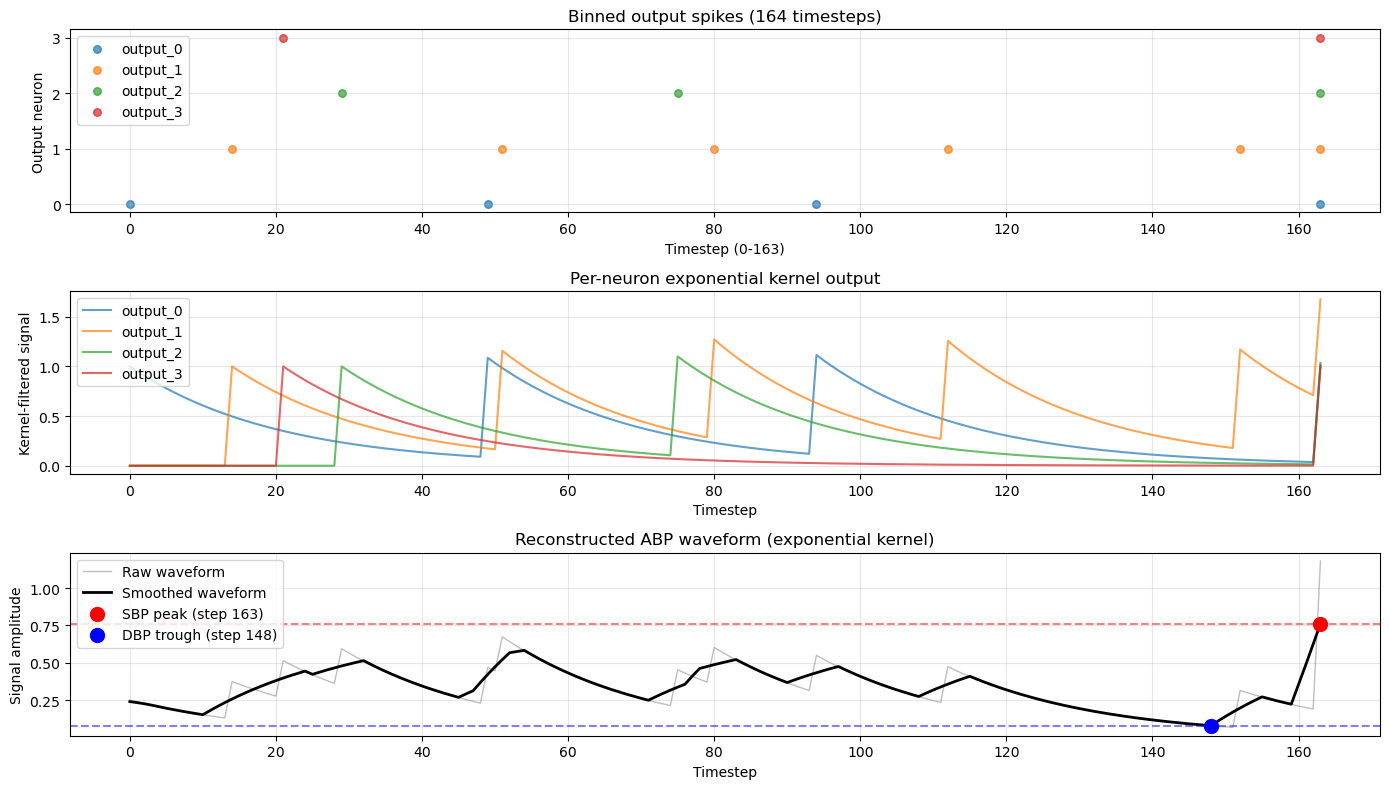


SBP peak at step 163: amplitude 0.7609
DBP trough at step 148: amplitude 0.0786

Note: these amplitudes are in arbitrary kernel units, not mmHg.
In your training code, the kernel output is scaled by SCALING_FACTOR
and compared against (abp / 100.0). To get mmHg, multiply by 100.

Estimated SBP: 76.1 mmHg
Estimated DBP: 7.9 mmHg
True values for this sample: SBP=112.7, DBP=64.4


In [32]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8))

# Plot 1: Spike matrix as raster
ax = axes[0]
for i, log_id in enumerate(output_logic):
    spike_times_binned = np.where(spike_matrix[:, i] > 0)[0]
    ax.scatter(spike_times_binned, [i] * len(spike_times_binned), s=30, alpha=0.7,
              label=f'output_{log_id}')
ax.set_xlabel('Timestep (0-163)')
ax.set_ylabel('Output neuron')
ax.set_title('Binned output spikes (164 timesteps)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Per-neuron kernel signal
ax = axes[1]
for i, log_id in enumerate(output_logic):
    ax.plot(signal[:, i], label=f'output_{log_id}', alpha=0.7)
ax.set_xlabel('Timestep')
ax.set_ylabel('Kernel-filtered signal')
ax.set_title('Per-neuron exponential kernel output')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Averaged waveform with SBP/DBP extraction
ax = axes[2]
ax.plot(waveform_raw, color='gray', linewidth=1, alpha=0.5, label='Raw waveform')
ax.plot(waveform, color='black', linewidth=2, label='Smoothed waveform')

# Extract SBP and DBP as max and min of the waveform
sbp_step = np.argmax(waveform)
dbp_step = np.argmin(waveform[1:]) + 1  # skip step 0 to avoid edge effects
sbp_val = waveform[sbp_step]
dbp_val = waveform[dbp_step]

ax.axhline(y=sbp_val, color='red', linestyle='--', alpha=0.5)
ax.axhline(y=dbp_val, color='blue', linestyle='--', alpha=0.5)
ax.scatter([sbp_step], [sbp_val], color='red', s=100, zorder=5, label=f'SBP peak (step {sbp_step})')
ax.scatter([dbp_step], [dbp_val], color='blue', s=100, zorder=5, label=f'DBP trough (step {dbp_step})')

ax.set_xlabel('Timestep')
ax.set_ylabel('Signal amplitude')
ax.set_title('Reconstructed ABP waveform (exponential kernel)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\nSBP peak at step {sbp_step}: amplitude {sbp_val:.4f}')
print(f'DBP trough at step {dbp_step}: amplitude {dbp_val:.4f}')
print(f'\nNote: these amplitudes are in arbitrary kernel units, not mmHg.')
print(f'In your training code, the kernel output is scaled by SCALING_FACTOR')
print(f'and compared against (abp / 100.0). To get mmHg, multiply by 100.')
print(f'\nEstimated SBP: {sbp_val * 100:.1f} mmHg')
print(f'Estimated DBP: {dbp_val * 100:.1f} mmHg')
print(f'True values for this sample: SBP={df.iloc[sample_idx]["SP"]:.1f}, DBP={df.iloc[sample_idx]["DP"]:.1f}')

## Plotting & Biases Check

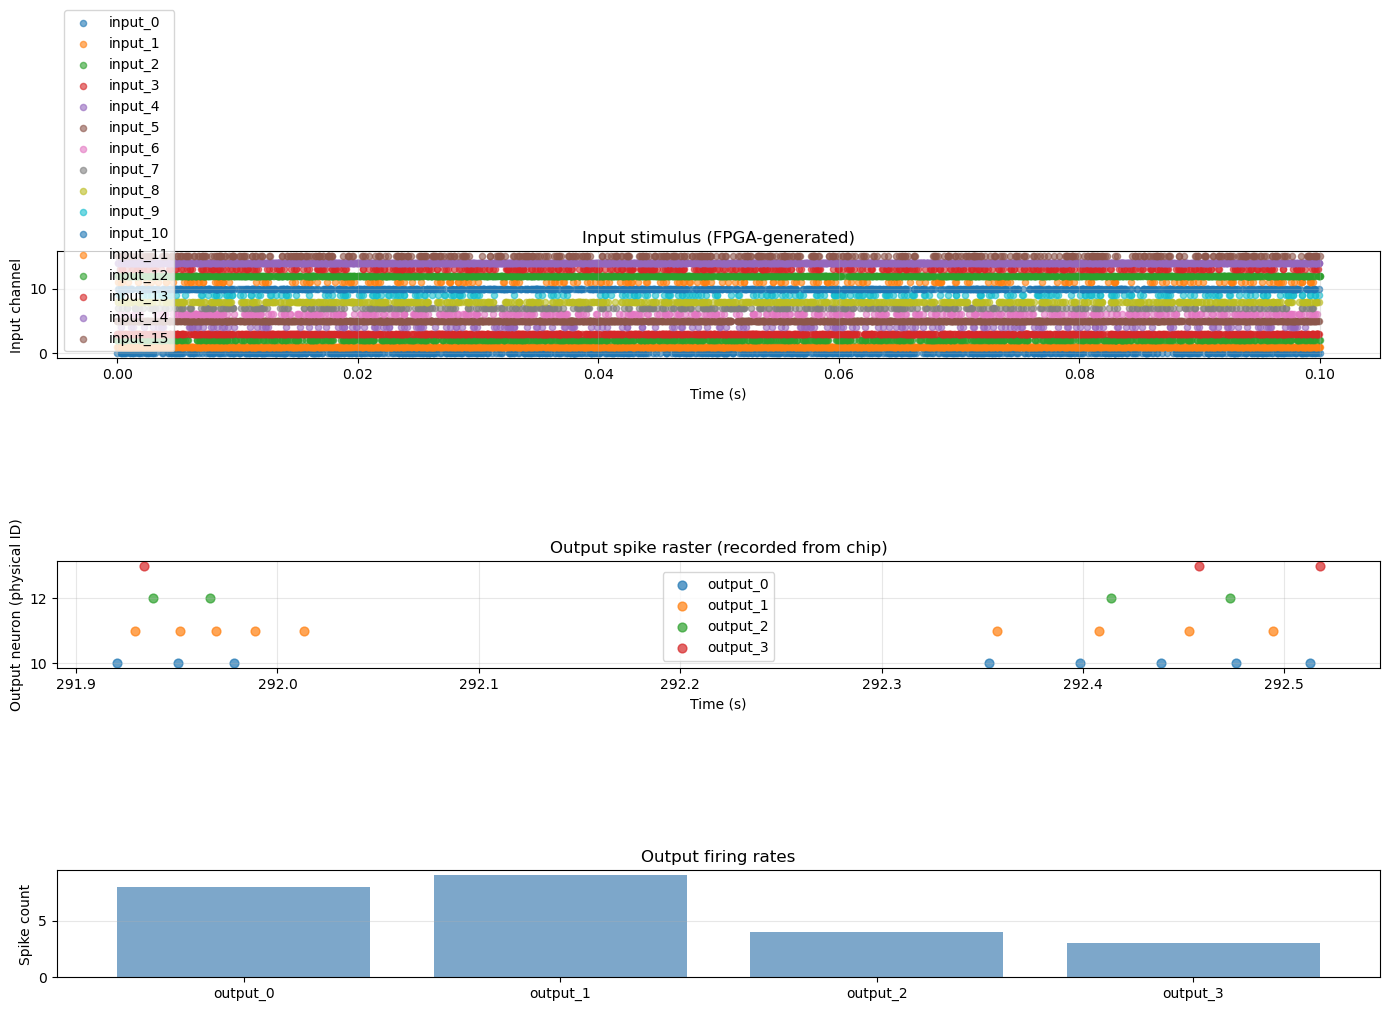

HIDDEN spikes: 646
OUTPUT spikes: 24

Done!


In [33]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8))

# Plot 1: Input spike train
ax = axes[0]
for ch in input_layer:
    ch_times = spike_times[spike_indices == ch]
    ax.scatter(ch_times, [ch]*len(ch_times), s=20, alpha=0.6, label=f'input_{ch}')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Input channel')
ax.set_title('Input stimulus (FPGA-generated)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Output spike raster
ax = axes[1]
if recorded_events:
    out_times_s = np.array([e.timestamp for e in recorded_events]) * 1e-6
    out_neurons = np.array([e.neuron_id for e in recorded_events])
    for phys_id, log_id in zip(output_physicals, output_logic):
        mask = out_neurons == phys_id
        if mask.any():
            ax.scatter(out_times_s[mask], [phys_id]*mask.sum(), s=40, alpha=0.7, 
                      label=f'output_{log_id}')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Output neuron (physical ID)')
    ax.set_title('Output spike raster (recorded from chip)')
    ax.legend()
    ax.grid(True, alpha=0.3)
else:
    ax.text(0.5, 0.5, 'No output spikes', ha='center', va='center',
            transform=ax.transAxes, fontsize=14, color='red', weight='bold')

# Plot 3: Spike counts
ax = axes[2]
if recorded_events:
    out_neurons = np.array([e.neuron_id for e in recorded_events])
    unique, counts = np.unique(out_neurons, return_counts=True)
    labels = [f'output_{output_logic[i]}' for i, p in enumerate(output_physicals) if p in unique]
    counts_for_labels = [counts[list(unique).index(output_physicals[i])] 
                         for i in range(len(output_logic)) if output_physicals[i] in unique]
    if labels:
        ax.bar(labels, counts_for_labels, color='steelblue', alpha=0.7)
    ax.set_ylabel('Spike count')
    ax.set_title('Output firing rates')
    ax.grid(True, alpha=0.3, axis='y')
else:
    ax.text(0.5, 0.5, 'No output spikes', ha='center', va='center',
            transform=ax.transAxes, fontsize=14, color='red', weight='bold')

plt.tight_layout()
plt.show()

print(f'HIDDEN spikes: {len(hidden_events)}')
print(f'OUTPUT spikes: {len(recorded_events)}')

print('\nDone!')

In [ ]:
config = model.get_configuration()
for (cid, core), label in [(HIDDEN_CORE, 'HIDDEN'), (OUTPUT_CORE, 'OUTPUT')]:
    pg = config.chips[cid].cores[core].parameter_group
    print(f'--- {label} core (chip {cid}, core {core}) ---')
    for p in ['IF_RFR_N', 'IF_CASC_N', 'IF_AHW_P', 'IF_AHTHR_N', 'IF_AHTAU_N',
              'PULSE_PWLK_P', 'IF_TAU1_N', 'IF_THR_N', 'IF_DC_P',
              'PS_WEIGHT_EXC_F_N', 'NPDPIE_THR_F_P', 'NPDPIE_TAU_F_P']:
        try:
            prm = pg.param_map[p]
            print(f'  {p:20s} coarse={prm.coarse_value:2d}  fine={prm.fine_value:3d}')
        except Exception as e:
            print(f'  {p:20s} <error: {e}>')

NameError: name 'HIDDEN_CORE' is not defined